In [1]:
!pip -q install lightgbm pyyaml

from google.colab import drive
drive.mount('/content/drive')

import json
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, accuracy_score

PROJECT_DIR = "/content/drive/MyDrive/fintech_theme3"
DATA_DIR = f"{PROJECT_DIR}/data"

train = pd.read_csv(f"{DATA_DIR}/train_fe.csv", parse_dates=["Date"])
valid = pd.read_csv(f"{DATA_DIR}/valid_fe.csv", parse_dates=["Date"])
# test не загружаем — он понадобится только на этапе 4

with open(f"{DATA_DIR}/baseline_metrics.json") as f:
    baseline = json.load(f)

ALL_FEATURES = ["ret_1", "ret_5", "ret_20", "momentum_60", "volatility_5",
                "volatility_20", "ma_ratio_20", "ma_ratio_60", "volume_change",
                "relative_volume_20", "rsi_14", "macd", "zscore_20", "vol_ratio",
                "drawdown_252", "mom_12_1", "volume_trend", "mkt_ret_5",
                "mkt_vol_20", "rel_ret_20", "rank_ret_20"]

X_train, y_train = train[ALL_FEATURES], train["target"]
X_valid, y_valid = valid[ALL_FEATURES], valid["target"]
print("Планка (LogReg):", baseline)

Mounted at /content/drive
Планка (LogReg): {'model': 'LogReg', 'C': 0.0001, 'ROC-AUC': 0.5064, 'Gini': 0.0129}


In [2]:
from itertools import product

grid = {
    "num_leaves":        [7, 15, 31],
    "min_child_samples": [200, 500, 1000],
    "reg_lambda":        [0.0, 5.0],
}

rows, models = [], {}
for num_leaves, min_child, reg_lambda in product(*grid.values()):
    params = dict(
        n_estimators=3000, learning_rate=0.01,
        num_leaves=num_leaves, min_child_samples=min_child, reg_lambda=reg_lambda,
        subsample=0.8, subsample_freq=1,    # без subsample_freq подвыборка не включается
        colsample_bytree=0.8,
        metric="auc", random_state=42, verbose=-1,
    )
    model = lgb.LGBMClassifier(**params)
    model.fit(X_train, y_train,
              eval_set=[(X_valid, y_valid)],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    auc = model.best_score_["valid_0"]["auc"]
    key = (num_leaves, min_child, reg_lambda)
    models[key] = model
    rows.append({"num_leaves": num_leaves, "min_child_samples": min_child,
                 "reg_lambda": reg_lambda, "best_iteration": model.best_iteration_,
                 "ROC-AUC": round(auc, 4), "Gini": round(2 * auc - 1, 4)})

search = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False)
display(search)
search.to_csv(f"{PROJECT_DIR}/lgbm_search.csv", index=False)

,num_leaves,min_child_samples,reg_lambda,best_iteration,ROC-AUC,Gini
4,7,1000,0.0,65,0.5356,0.0712
5,7,1000,5.0,65,0.5344,0.0687
0,7,200,0.0,8,0.5342,0.0683
3,7,500,5.0,34,0.5308,0.0616
2,7,500,0.0,8,0.5300,0.0599
1,7,200,5.0,45,0.5294,0.0588
17,31,1000,5.0,48,0.5279,0.0559
11,15,1000,5.0,48,0.5279,0.0559
7,15,200,5.0,6,0.5278,0.0557
6,15,200,0.0,21,0.5270,0.0540


In [3]:
best = search.iloc[0]
best_key = (int(best["num_leaves"]), int(best["min_child_samples"]), float(best["reg_lambda"]))
best_model = models[best_key]

p_valid = best_model.predict_proba(X_valid)[:, 1]
auc_lgb = roc_auc_score(y_valid, p_valid)

comparison = pd.DataFrame({
    "Логистическая регрессия": {"ROC-AUC": baseline["ROC-AUC"], "Gini": baseline["Gini"]},
    "LightGBM": {"ROC-AUC": round(auc_lgb, 4), "Gini": round(2 * auc_lgb - 1, 4)},
}).T
display(comparison)
comparison.to_csv(f"{PROJECT_DIR}/model_comparison.csv")

# Дополнительно: ROC-AUC на train (проверка переобучения)
p_train = best_model.predict_proba(X_train)[:, 1]
print("LightGBM ROC-AUC train:", round(roc_auc_score(y_train, p_train), 4),
      "| validation:", round(auc_lgb, 4))

,ROC-AUC,Gini
Логистическая регрессия,0.5064,0.0129
LightGBM,0.5356,0.0712


LightGBM ROC-AUC train: 0.5878 | validation: 0.5356


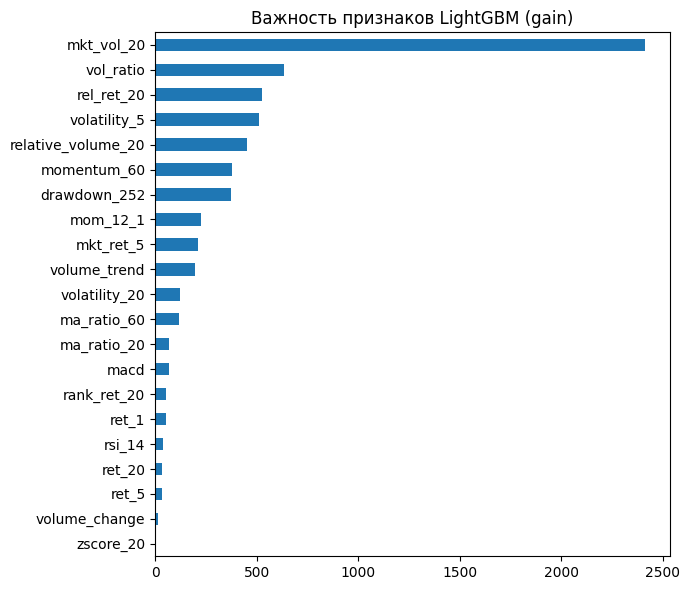

In [4]:
imp = pd.Series(best_model.booster_.feature_importance(importance_type="gain"),
                index=ALL_FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 6), title="Важность признаков LightGBM (gain)")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/fig_lgbm_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
import yaml, joblib

config = {
    "variant": 3,
    "target": "sign of 5-day forward return (shift(-5))",
    "features": ALL_FEATURES,
    "split": {"train": 0.70, "valid": 0.15, "test": 0.15, "gap_days": 5},
    "model": "LightGBM",
    "params": {
        "n_estimators": int(best_model.best_iteration_),
        "learning_rate": 0.01,
        "num_leaves": best_key[0],
        "min_child_samples": best_key[1],
        "reg_lambda": best_key[2],
        "subsample": 0.8, "subsample_freq": 1,
        "colsample_bytree": 0.8,
        "random_state": 42,
    },
    "validation_metrics": {"ROC-AUC": round(float(auc_lgb), 4),
                           "Gini": round(float(2 * auc_lgb - 1), 4)},
}
with open(f"{PROJECT_DIR}/config.yaml", "w") as f:
    yaml.safe_dump(config, f, allow_unicode=True, sort_keys=False)

joblib.dump(best_model, f"{PROJECT_DIR}/model_lgbm.pkl")
print(open(f"{PROJECT_DIR}/config.yaml").read())

variant: 3
target: sign of 5-day forward return (shift(-5))
features:
- ret_1
- ret_5
- ret_20
- momentum_60
- volatility_5
- volatility_20
- ma_ratio_20
- ma_ratio_60
- volume_change
- relative_volume_20
- rsi_14
- macd
- zscore_20
- vol_ratio
- drawdown_252
- mom_12_1
- volume_trend
- mkt_ret_5
- mkt_vol_20
- rel_ret_20
- rank_ret_20
split:
  train: 0.7
  valid: 0.15
  test: 0.15
  gap_days: 5
model: LightGBM
params:
  n_estimators: 65
  learning_rate: 0.01
  num_leaves: 7
  min_child_samples: 1000
  reg_lambda: 0.0
  subsample: 0.8
  subsample_freq: 1
  colsample_bytree: 0.8
  random_state: 42
validation_metrics:
  ROC-AUC: 0.5356
  Gini: 0.0712



Обучен LightGBM с ранней остановкой (100 итераций без улучшения ROC-AUC на validation); гиперпараметры подобраны перебором 18 комбинаций на validation без KFold. Лучшая модель — простая: num_leaves = 7, min_child_samples = 1000, learning_rate = 0.01, 65 деревьев; параметры сохранены в config.yaml. На validation LightGBM показал ROC-AUC = 0.536 (Gini = 0.071) против 0.506 (Gini = 0.013) у логистической регрессии, т. е. превзошёл базовую модель; более сложные конфигурации работали хуже, что говорит о слабом сигнале и риске переобучения. Наиболее важный признак — волатильность рынка за 20 дней (mkt_vol_20), далее отношение краткосрочной волатильности к месячной и относительная сила акции: модель в основном улавливает рыночный режим, причём нелинейно, чего не могла логистическая регрессия. Для финальной проверки на test выбран LightGBM.